In [39]:
%load_ext autoreload
%autoreload 2

from sklearn.manifold import MDS
import matplotlib.pyplot as plt
import torch
import numpy as np
from scipy.stats import spearmanr

import compcats.utils.responsecomparison_utils as rcutils
import compcats.utils.dimensionalityreduction_utils as drutils

import main_analysis as ma

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [31]:
def compute_pearson_correlation(rdm1, rdm2):
    """Compute the Pearson correlation between two RDM matrices."""
    assert rdm1.shape == rdm2.shape, "RDM matrices must have the same shape"

    # Flatten the upper triangular part (excluding diagonal)
    indices = torch.triu_indices(rdm1.shape[0], rdm1.shape[1], offset=1)
    rdm1_flat = rdm1[indices[0], indices[1]]
    rdm2_flat = rdm2[indices[0], indices[1]]

    # Compute Pearson correlation
    mean1, mean2 = rdm1_flat.mean(), rdm2_flat.mean()
    std1, std2 = rdm1_flat.std(unbiased=False), rdm2_flat.std(unbiased=False)

    correlation = ((rdm1_flat - mean1) * (rdm2_flat - mean2)).mean() / (std1 * std2)
    return correlation.item()

def calculate_stress(original_distances, projected_distances):
    """
    Calculate the Kruskal's Stress between two distance matrices.
    
    Args:
    original_distances (torch.Tensor): The original distance matrix (n x n).
    projected_distances (torch.Tensor): The distance matrix after MDS (n x n).
    
    Returns:
    torch.Tensor: The stress value.
    """
    # Compute the squared differences between the original and projected distances
    diff = original_distances - projected_distances
    squared_diff = diff ** 2
    
    # Calculate the sum of squared differences
    numerator = torch.sum(squared_diff)
    
    # Calculate the sum of squared original distances
    denominator = torch.sum(original_distances ** 2)
    
    # Calculate stress
    stress = torch.sqrt(numerator / denominator)
    
    return stress.item()

# MDS Univariate (non-normalized pearsonr)

In [19]:
model_fmri_frois = [
    ('FFA', 'FFA'),
    ('PPA', 'PPA'),
    ('EBA', 'EBA'),
]
fmri_frois = list({froi for froi, _ in model_fmri_frois})
tthreshold = 7
model_localizer = 'grillspector'

subjects_data, subjects_splithalf_pearsonrs, subjects_splithalf_rdmrs = \
    ma.get_allsubjects_nsd515_data(fmri_frois, tthreshold)
for froi in subjects_data.keys():
    for subject in subjects_data[froi].keys():
        subjects_data[froi][subject] = subjects_data[froi][subject].mean(axis=-1).cuda()
models_data = ma.get_allmodels_nsd515_data(
    model_fmri_frois, tthreshold, model_localizer, unitmean=True
)

Using cache found in /home/alishd/.cache/torch/hub/harvard-visionlab_open_ipcl_main


/home/alishd/.cache/torch/checkpoints/1a6IO4xhWy8cdyAuWv0BxSONz7lMcKbZE.pth.tar


/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Using cached ./models


Using cache found in /home/alishd/.cache/torch/hub/facebookresearch_dinov2_main
Using cache found in /home/alishd/.cache/torch/hub/facebookresearch_dinov2_main
Using cache found in /home/alishd/.cache/torch/hub/harvard-visionlab_open_ipcl_main


...

Using cache found in /home/alishd/.cache/torch/hub/facebookresearch_dinov2_main
Using cache found in /home/alishd/.cache/torch/hub/facebookresearch_dinov2_main
Using cache found in /home/alishd/.cache/torch/hub/harvard-visionlab_open_ipcl_main


/home/alishd/.cache/torch/checkpoints/1a6IO4xhWy8cdyAuWv0BxSONz7lMcKbZE.pth.tar


/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Using cached ./models


Using cache found in /home/alishd/.cache/torch/hub/facebookresearch_dinov2_main
Using cache found in /home/alishd/.cache/torch/hub/facebookresearch_dinov2_main


In [24]:
fmri_froi = 'FFA'
model_froi = 'FFA'
froi_subjects_data = subjects_data[fmri_froi]
froi_models_data = models_data[(model_froi, fmri_froi)]
froi_models_data = models_data[(model_froi, fmri_froi)]
froi_subjects_splithalf_pearsonrs = subjects_splithalf_pearsonrs[fmri_froi]

keys = list(froi_subjects_data.keys()) + list(froi_models_data.keys())
froi_splithalf_pearsonr_vector = []
for key in keys:
    if key in froi_subjects_splithalf_pearsonrs:
        froi_splithalf_pearsonr_vector.append(froi_subjects_splithalf_pearsonrs[key])
    elif key in froi_models_data:
        froi_splithalf_pearsonr_vector.append(1)

# Compute reliability matrix
reliability_vector = torch.tensor(froi_splithalf_pearsonr_vector)
reliability_matrix = torch.sqrt(reliability_vector[:, None] * reliability_vector[None, :])
# Ensure diagonal elements are 1
diag_indices = torch.arange(reliability_matrix.shape[0])
reliability_matrix[diag_indices, diag_indices] = 1.0

## Normalized correlation distances (Clamped)

Computing MDS for FFA and FFA
Ignoring resnet50imagenet21k model for FFA and FFA
54 our of 1444 values are negative, clamping to 1e-05
Stress: 0.2051934152841568
Spearman rank correlation between original and MDS distances: 0.912 (p=2.250e-12)


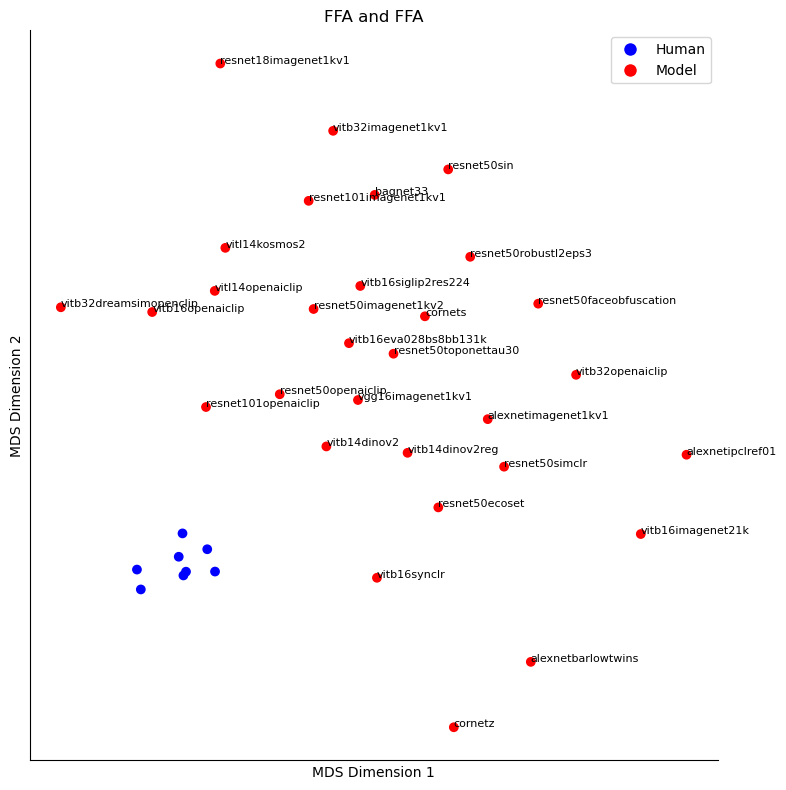

Computing MDS for PPA and PPA
Ignoring resnet50imagenet21k model for PPA and PPA
76 our of 1444 values are negative, clamping to 1e-05
Stress: 0.2436719387769699
Spearman rank correlation between original and MDS distances: 0.856 (p=1.661e-09)


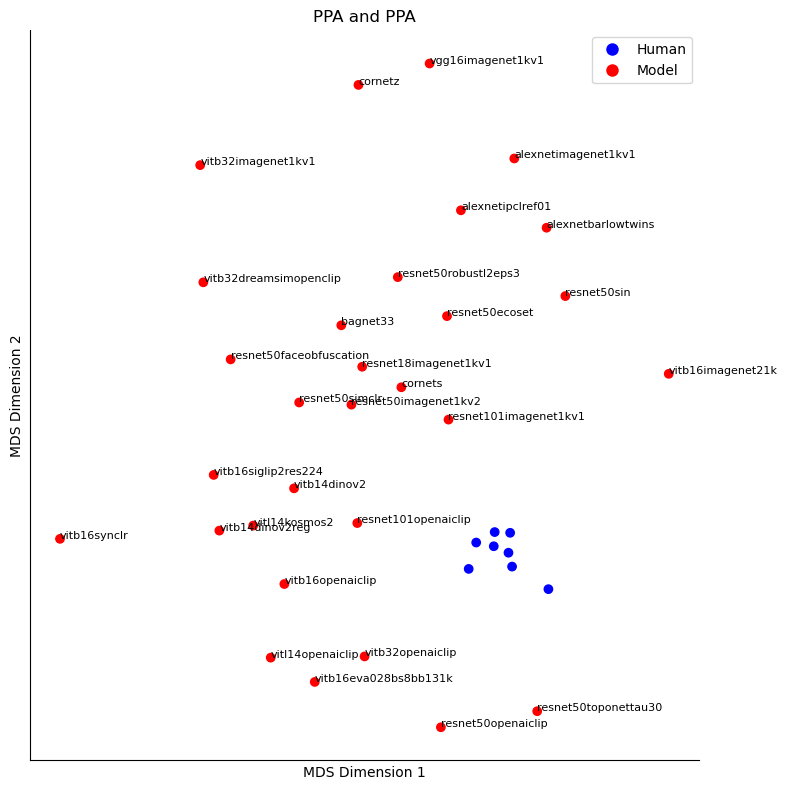

Computing MDS for EBA and EBA
Ignoring resnet50imagenet21k model for EBA and EBA
64 our of 1444 values are negative, clamping to 1e-05
Stress: 0.2405964881181717
Spearman rank correlation between original and MDS distances: 0.837 (p=8.394e-09)


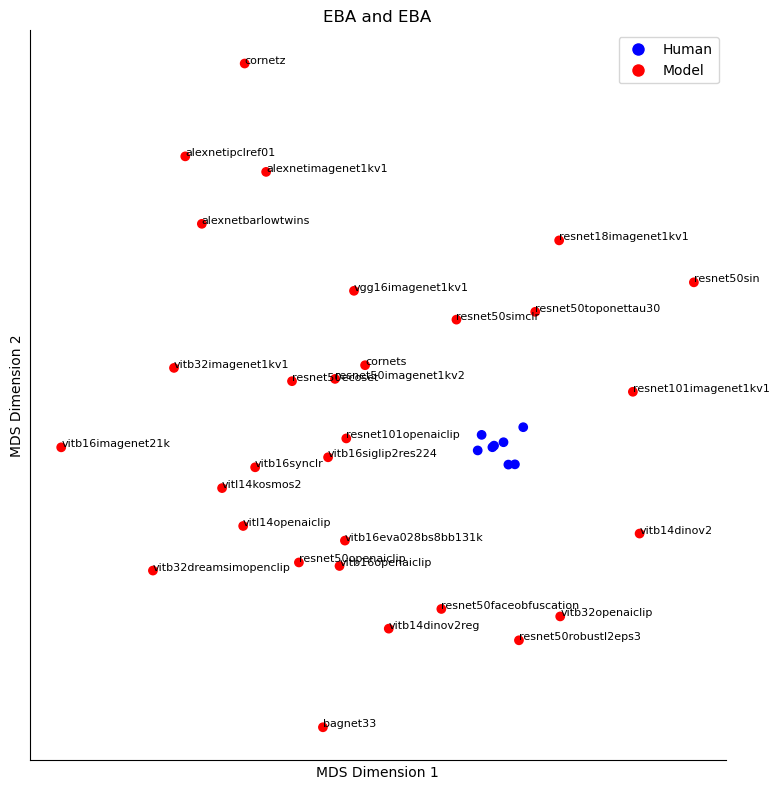

In [42]:
annotate_models = True

for (model_froi, fmri_froi) in model_fmri_frois:
    print(f'Computing MDS for {model_froi} and {fmri_froi}')
    froi_subjects_data = subjects_data[fmri_froi]
    froi_models_data = models_data[(model_froi, fmri_froi)]
    # Ignore resnet50imagenet21k model
    if 'resnet50imagenet21k' in froi_models_data:
        print(f"Ignoring resnet50imagenet21k model for {model_froi} and {fmri_froi}")
        del froi_models_data['resnet50imagenet21k']
    froi_subjects_splithalf_pearsonrs = subjects_splithalf_pearsonrs[fmri_froi]

    keys = list(froi_subjects_data.keys()) + list(froi_models_data.keys())
    froi_splithalf_pearsonr_vector = []
    for key in keys:
        if key in froi_subjects_splithalf_pearsonrs:
            froi_splithalf_pearsonr_vector.append(froi_subjects_splithalf_pearsonrs[key])
        elif key in froi_models_data:
            froi_splithalf_pearsonr_vector.append(1)

    # Compute reliability matrix
    reliability_vector = torch.tensor(froi_splithalf_pearsonr_vector)
    reliability_matrix = torch.sqrt(reliability_vector[:, None] * reliability_vector[None, :])
    # Ensure diagonal elements are 1
    diag_indices = torch.arange(reliability_matrix.shape[0])
    reliability_matrix[diag_indices, diag_indices] = 1.0

    responses = []
    for key in keys:
        if key in froi_subjects_data:
            responses.append(froi_subjects_data[key])
        elif key in froi_models_data:
            responses.append(froi_models_data[key])

    responses = torch.stack(responses, dim=0)

    # Compute pairwise distances
    n_systems = responses.shape[0]
    distances = torch.zeros((n_systems, n_systems))

    for i in range(n_systems):
        for j in range(i + 1, n_systems):  # Compute only upper triangular (symmetric)
            dist = 1 - (rcutils.pearsonr(responses[i], responses[j]) / reliability_matrix[i, j])
            distances[i, j] = dist
            distances[j, i] = dist  # Symmetric matrix

    epsilon = 1e-5
    print(f'{distances[distances<=0].numel()} our of {distances.numel()} values are negative, clamping to {epsilon}')
    distances = torch.clamp(distances, min=epsilon)

    mds = MDS(n_components=2, dissimilarity='precomputed')
    mds_coords = mds.fit_transform(distances.cpu().numpy())

    # Test if MDS distances are correct
    mds_coords_tensor = torch.tensor(mds_coords)
    n_systems = len(keys)
    lowdim_distances = torch.zeros((n_systems, n_systems))
    for i in range(n_systems):
        for j in range(i + 1, n_systems):  # Compute only upper triangular (symmetric)
            dist = torch.norm(mds_coords_tensor[i] - mds_coords_tensor[j])
            lowdim_distances[i, j] = dist
            lowdim_distances[j, i] = dist  # Symmetric matrix
    print('Stress:', calculate_stress(distances, lowdim_distances))

    # Find which indices correspond to subjects and which to models
    subject_indices = [i for i, key in enumerate(keys) if key in froi_subjects_data]
    model_indices = [i for i, key in enumerate(keys) if key in froi_models_data]

    # Calculate mean distances from each model to all subjects
    model_to_subjects_orig = torch.zeros(len(model_indices))
    model_to_subjects_mds = torch.zeros(len(model_indices))

    for i, model_idx in enumerate(model_indices):
        # Mean distance from this model to all subjects in original space
        model_to_subjects_orig[i] = distances[model_idx, subject_indices].mean()
        
        # Mean distance from this model to all subjects in MDS space
        model_to_subjects_mds[i] = lowdim_distances[model_idx, subject_indices].mean()

    # Calculate Spearman rank correlation
    sp_corr, p_value = spearmanr(model_to_subjects_orig.numpy(), model_to_subjects_mds.numpy())

    print(f"Spearman rank correlation between original and MDS distances: {sp_corr:.3f} (p={p_value:.3e})")

    human_color = 'blue'
    model_color = 'red'
    colors = [human_color if key in froi_subjects_data else model_color for key in keys]
    plt.figure(figsize=(8, 8))
    plt.scatter(mds_coords[:, 0], mds_coords[:, 1], c=colors)

    if annotate_models:
        for i, key in enumerate(keys):
            if key in froi_models_data:
                plt.annotate(key, (mds_coords[i, 0], mds_coords[i, 1]), fontsize=8)

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.xticks([])
    plt.yticks([])
    plt.xlabel('MDS Dimension 1')
    plt.ylabel('MDS Dimension 2')
    plt.legend(handles=[plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=human_color, markersize=10, label='Human'),
                        plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=model_color, markersize=10, label='Model')],
            loc='best')
    plt.title(f'{model_froi} and {fmri_froi}')
    plt.tight_layout()
    plt.show()

## Non-normalized pearson correlation distances

Computing MDS for FFA and FFA
38 our of 1444 values are negative, clamping to 1e-05
Stress: 0.21250206232070923
Spearman rank correlation between original and MDS distances: 0.906 (p=6.025e-12)


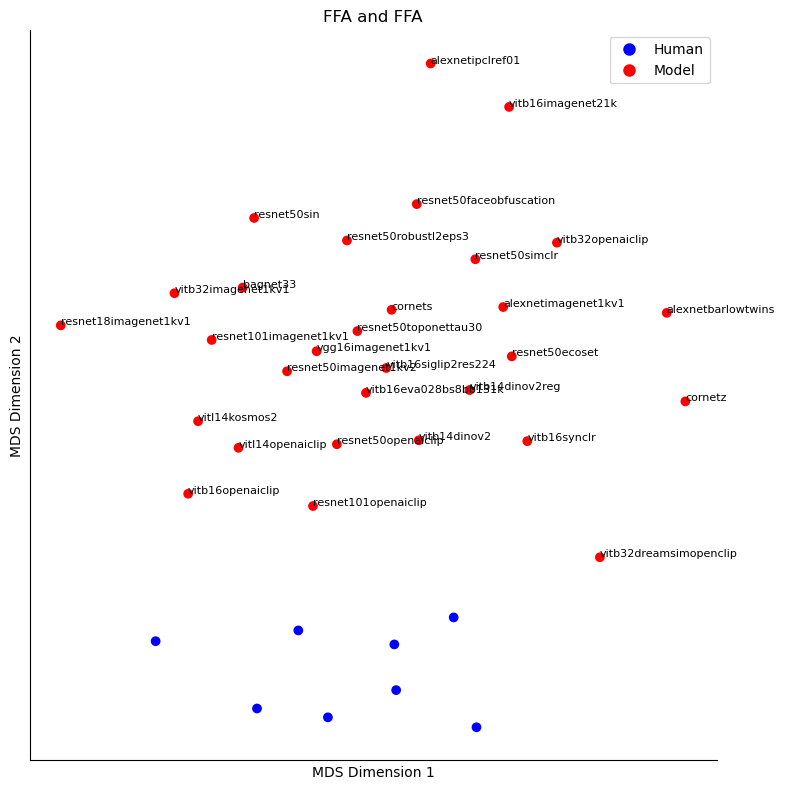

Computing MDS for PPA and PPA
38 our of 1444 values are negative, clamping to 1e-05
Stress: 0.2527449429035187
Spearman rank correlation between original and MDS distances: 0.811 (p=5.363e-08)


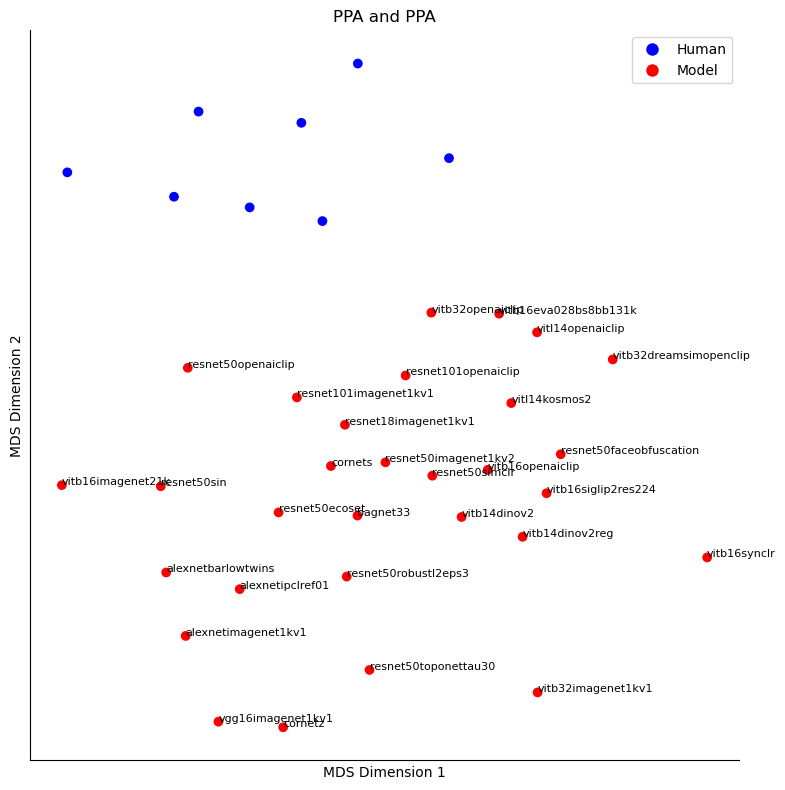

Computing MDS for EBA and EBA
38 our of 1444 values are negative, clamping to 1e-05
Stress: 0.26642459630966187
Spearman rank correlation between original and MDS distances: 0.784 (p=3.016e-07)


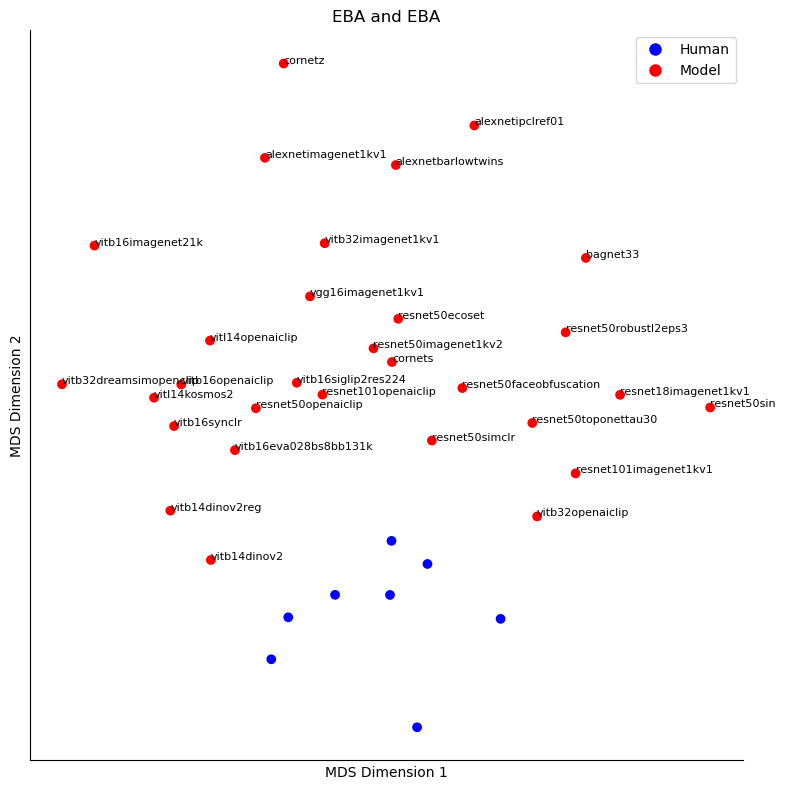

In [43]:
annotate_models = True

for (model_froi, fmri_froi) in model_fmri_frois:
    print(f'Computing MDS for {model_froi} and {fmri_froi}')
    froi_subjects_data = subjects_data[fmri_froi]
    froi_models_data = models_data[(model_froi, fmri_froi)]
    # Ignore resnet50imagenet21k model
    if 'resnet50imagenet21k' in froi_models_data:
        print(f"Ignoring resnet50imagenet21k model for {model_froi} and {fmri_froi}")
        del froi_models_data['resnet50imagenet21k']
    froi_subjects_splithalf_pearsonrs = subjects_splithalf_pearsonrs[fmri_froi]

    keys = list(froi_subjects_data.keys()) + list(froi_models_data.keys())
    froi_splithalf_pearsonr_vector = []
    for key in keys:
        if key in froi_subjects_splithalf_pearsonrs:
            froi_splithalf_pearsonr_vector.append(froi_subjects_splithalf_pearsonrs[key])
        elif key in froi_models_data:
            froi_splithalf_pearsonr_vector.append(1)

    # Compute reliability matrix
    reliability_vector = torch.tensor(froi_splithalf_pearsonr_vector)
    reliability_matrix = torch.sqrt(reliability_vector[:, None] * reliability_vector[None, :])
    # Ensure diagonal elements are 1
    diag_indices = torch.arange(reliability_matrix.shape[0])
    reliability_matrix[diag_indices, diag_indices] = 1.0

    responses = []
    for key in keys:
        if key in froi_subjects_data:
            responses.append(froi_subjects_data[key])
        elif key in froi_models_data:
            responses.append(froi_models_data[key])

    responses = torch.stack(responses, dim=0)

    # Compute pairwise distances
    n_systems = responses.shape[0]
    distances = torch.zeros((n_systems, n_systems))

    for i in range(n_systems):
        for j in range(i + 1, n_systems):  # Compute only upper triangular (symmetric)
            dist = 1 - rcutils.pearsonr(responses[i], responses[j])
            distances[i, j] = dist
            distances[j, i] = dist  # Symmetric matrix

    epsilon = 1e-5
    print(f'{distances[distances<=0].numel()} our of {distances.numel()} values are negative, clamping to {epsilon}')
    distances = torch.clamp(distances, min=epsilon)

    mds = MDS(n_components=2, dissimilarity='precomputed')
    mds_coords = mds.fit_transform(distances.cpu().numpy())

    # Test if MDS distances are correct
    mds_coords_tensor = torch.tensor(mds_coords)
    n_systems = len(keys)
    lowdim_distances = torch.zeros((n_systems, n_systems))
    for i in range(n_systems):
        for j in range(i + 1, n_systems):  # Compute only upper triangular (symmetric)
            dist = torch.norm(mds_coords_tensor[i] - mds_coords_tensor[j])
            lowdim_distances[i, j] = dist
            lowdim_distances[j, i] = dist  # Symmetric matrix
    print('Stress:', calculate_stress(distances, lowdim_distances))

    # Find which indices correspond to subjects and which to models
    subject_indices = [i for i, key in enumerate(keys) if key in froi_subjects_data]
    model_indices = [i for i, key in enumerate(keys) if key in froi_models_data]

    # Calculate mean distances from each model to all subjects
    model_to_subjects_orig = torch.zeros(len(model_indices))
    model_to_subjects_mds = torch.zeros(len(model_indices))

    for i, model_idx in enumerate(model_indices):
        # Mean distance from this model to all subjects in original space
        model_to_subjects_orig[i] = distances[model_idx, subject_indices].mean()
        
        # Mean distance from this model to all subjects in MDS space
        model_to_subjects_mds[i] = lowdim_distances[model_idx, subject_indices].mean()

    # Calculate Spearman rank correlation
    sp_corr, p_value = spearmanr(model_to_subjects_orig.numpy(), model_to_subjects_mds.numpy())

    print(f"Spearman rank correlation between original and MDS distances: {sp_corr:.3f} (p={p_value:.3e})")

    human_color = 'blue'
    model_color = 'red'
    colors = [human_color if key in froi_subjects_data else model_color for key in keys]
    plt.figure(figsize=(8, 8))
    plt.scatter(mds_coords[:, 0], mds_coords[:, 1], c=colors)

    if annotate_models:
        for i, key in enumerate(keys):
            if key in froi_models_data:
                plt.annotate(key, (mds_coords[i, 0], mds_coords[i, 1]), fontsize=8)

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.xticks([])
    plt.yticks([])
    plt.xlabel('MDS Dimension 1')
    plt.ylabel('MDS Dimension 2')
    plt.legend(handles=[plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=human_color, markersize=10, label='Human'),
                        plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=model_color, markersize=10, label='Model')],
            loc='best')
    plt.title(f'{model_froi} and {fmri_froi}')
    plt.tight_layout()
    plt.show()

## Z-scored non-normalized euclidean distances

Computing MDS for FFA and FFA
38 our of 1444 values are negative, clamping to 1e-05
Stress: 0.29478612542152405
Spearman rank correlation between original and MDS distances: 0.858 (p=1.412e-09)


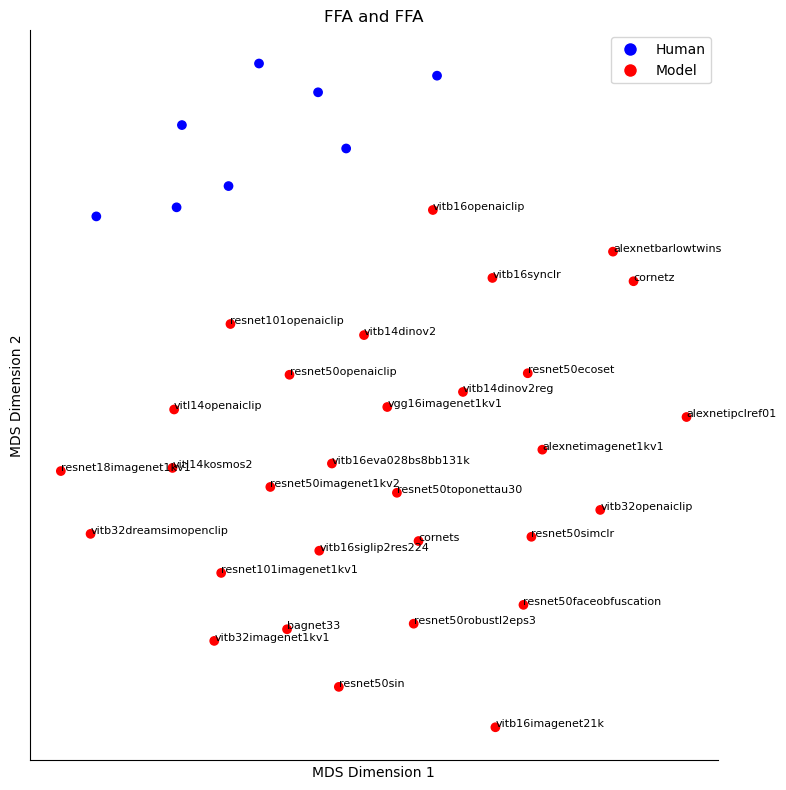

Computing MDS for PPA and PPA
38 our of 1444 values are negative, clamping to 1e-05
Stress: 0.3265364468097687
Spearman rank correlation between original and MDS distances: 0.751 (p=1.756e-06)


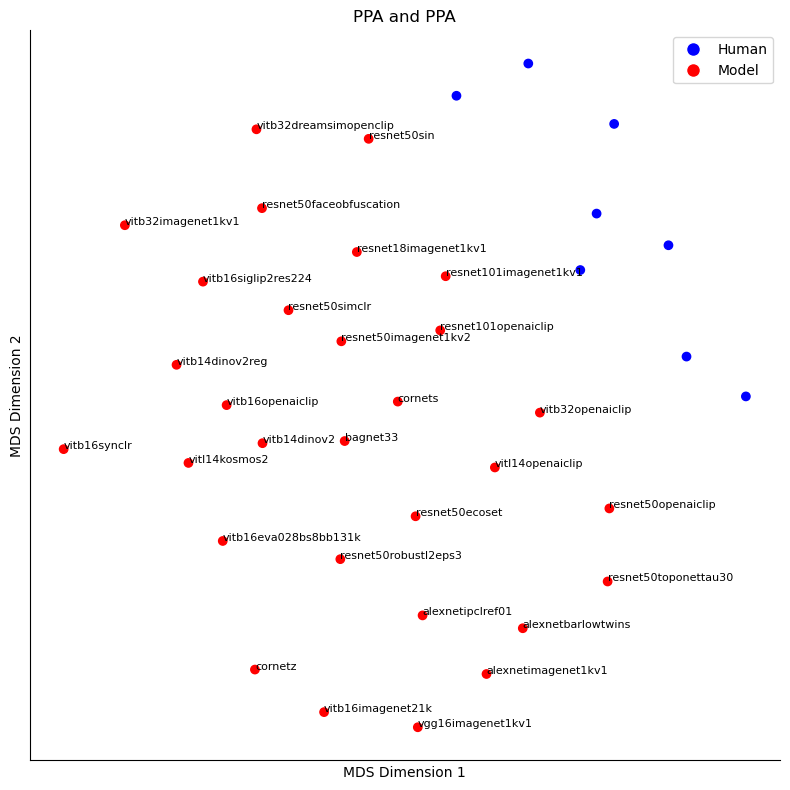

Computing MDS for EBA and EBA
38 our of 1444 values are negative, clamping to 1e-05
Stress: 0.3254140615463257
Spearman rank correlation between original and MDS distances: 0.745 (p=2.279e-06)


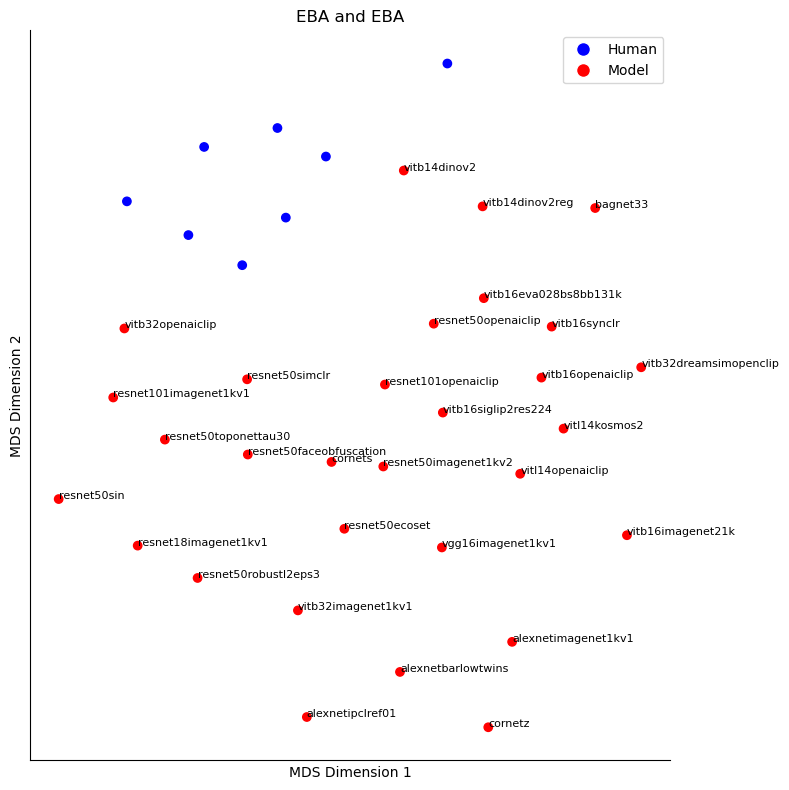

In [44]:
annotate_models = True

for (model_froi, fmri_froi) in model_fmri_frois:
    print(f'Computing MDS for {model_froi} and {fmri_froi}')
    froi_subjects_data = subjects_data[fmri_froi]
    froi_models_data = models_data[(model_froi, fmri_froi)]
    # Ignore resnet50imagenet21k model
    if 'resnet50imagenet21k' in froi_models_data:
        print(f"Ignoring resnet50imagenet21k model for {model_froi} and {fmri_froi}")
        del froi_models_data['resnet50imagenet21k']
    froi_subjects_splithalf_pearsonrs = subjects_splithalf_pearsonrs[fmri_froi]

    keys = list(froi_subjects_data.keys()) + list(froi_models_data.keys())
    froi_splithalf_pearsonr_vector = []
    for key in keys:
        if key in froi_subjects_splithalf_pearsonrs:
            froi_splithalf_pearsonr_vector.append(froi_subjects_splithalf_pearsonrs[key])
        elif key in froi_models_data:
            froi_splithalf_pearsonr_vector.append(1)

    # Compute reliability matrix
    reliability_vector = torch.tensor(froi_splithalf_pearsonr_vector)
    reliability_matrix = torch.sqrt(reliability_vector[:, None] * reliability_vector[None, :])
    # Ensure diagonal elements are 1
    diag_indices = torch.arange(reliability_matrix.shape[0])
    reliability_matrix[diag_indices, diag_indices] = 1.0

    responses = []
    for key in keys:
        if key in froi_subjects_data:
            responses.append(froi_subjects_data[key])
        elif key in froi_models_data:
            responses.append(froi_models_data[key])

    responses = torch.stack(responses, dim=0)

    # Compute pairwise distances
    n_systems = responses.shape[0]
    distances = torch.zeros((n_systems, n_systems))

    for i in range(n_systems):
        for j in range(i + 1, n_systems):  # Compute only upper triangular (symmetric)
            resp_i = (responses[i] - responses[i].mean()) / responses[i].std()
            resp_j = (responses[j] - responses[j].mean()) / responses[j].std()
            dist = torch.norm(resp_i - resp_j)
            distances[i, j] = dist
            distances[j, i] = dist  # Symmetric matrix

    epsilon = 1e-5
    print(f'{distances[distances<=0].numel()} our of {distances.numel()} values are negative, clamping to {epsilon}')
    distances = torch.clamp(distances, min=epsilon)

    mds = MDS(n_components=2, dissimilarity='precomputed')
    mds_coords = mds.fit_transform(distances.cpu().numpy())

    # Test if MDS distances are correct
    mds_coords_tensor = torch.tensor(mds_coords)
    n_systems = len(keys)
    lowdim_distances = torch.zeros((n_systems, n_systems))
    for i in range(n_systems):
        for j in range(i + 1, n_systems):  # Compute only upper triangular (symmetric)
            dist = torch.norm(mds_coords_tensor[i] - mds_coords_tensor[j])
            lowdim_distances[i, j] = dist
            lowdim_distances[j, i] = dist  # Symmetric matrix
    print('Stress:', calculate_stress(distances, lowdim_distances))

    # Find which indices correspond to subjects and which to models
    subject_indices = [i for i, key in enumerate(keys) if key in froi_subjects_data]
    model_indices = [i for i, key in enumerate(keys) if key in froi_models_data]

    # Calculate mean distances from each model to all subjects
    model_to_subjects_orig = torch.zeros(len(model_indices))
    model_to_subjects_mds = torch.zeros(len(model_indices))

    for i, model_idx in enumerate(model_indices):
        # Mean distance from this model to all subjects in original space
        model_to_subjects_orig[i] = distances[model_idx, subject_indices].mean()
        
        # Mean distance from this model to all subjects in MDS space
        model_to_subjects_mds[i] = lowdim_distances[model_idx, subject_indices].mean()

    # Calculate Spearman rank correlation
    sp_corr, p_value = spearmanr(model_to_subjects_orig.numpy(), model_to_subjects_mds.numpy())

    print(f"Spearman rank correlation between original and MDS distances: {sp_corr:.3f} (p={p_value:.3e})")

    human_color = 'blue'
    model_color = 'red'
    colors = [human_color if key in froi_subjects_data else model_color for key in keys]
    plt.figure(figsize=(8, 8))
    plt.scatter(mds_coords[:, 0], mds_coords[:, 1], c=colors)

    if annotate_models:
        for i, key in enumerate(keys):
            if key in froi_models_data:
                plt.annotate(key, (mds_coords[i, 0], mds_coords[i, 1]), fontsize=8)

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.xticks([])
    plt.yticks([])
    plt.xlabel('MDS Dimension 1')
    plt.ylabel('MDS Dimension 2')
    plt.legend(handles=[plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=human_color, markersize=10, label='Human'),
                        plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=model_color, markersize=10, label='Model')],
            loc='best')
    plt.title(f'{model_froi} and {fmri_froi}')
    plt.tight_layout()
    plt.show()

## Mahlanobis distances

Computing MDS for FFA and FFA
38 out of 1444 values are negative, clamping to 1e-05
Stress: 0.3142889738082886
Spearman rank correlation between original and MDS distances: 0.980 (p=3.607e-21)


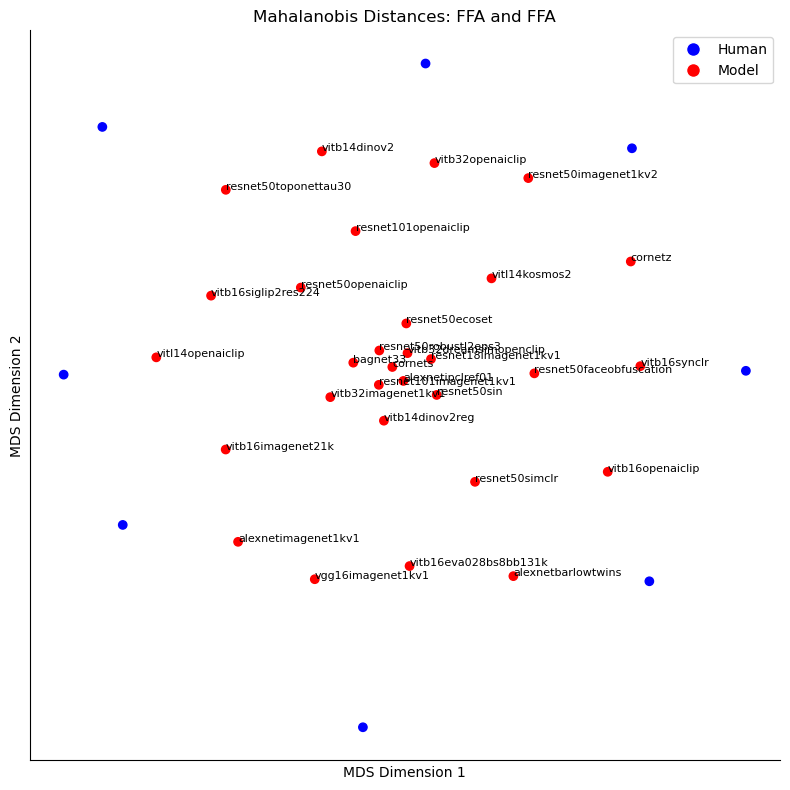

Computing MDS for PPA and PPA
38 out of 1444 values are negative, clamping to 1e-05
Stress: 0.3093118965625763
Spearman rank correlation between original and MDS distances: 0.928 (p=1.475e-13)


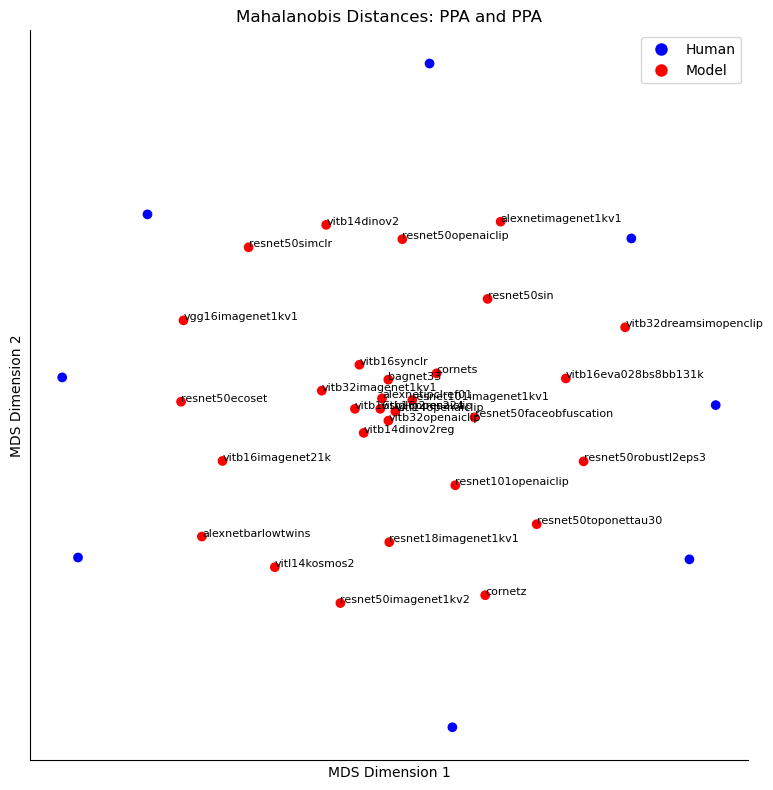

Computing MDS for EBA and EBA
38 out of 1444 values are negative, clamping to 1e-05
Stress: 0.33496037125587463
Spearman rank correlation between original and MDS distances: 0.648 (p=1.079e-04)


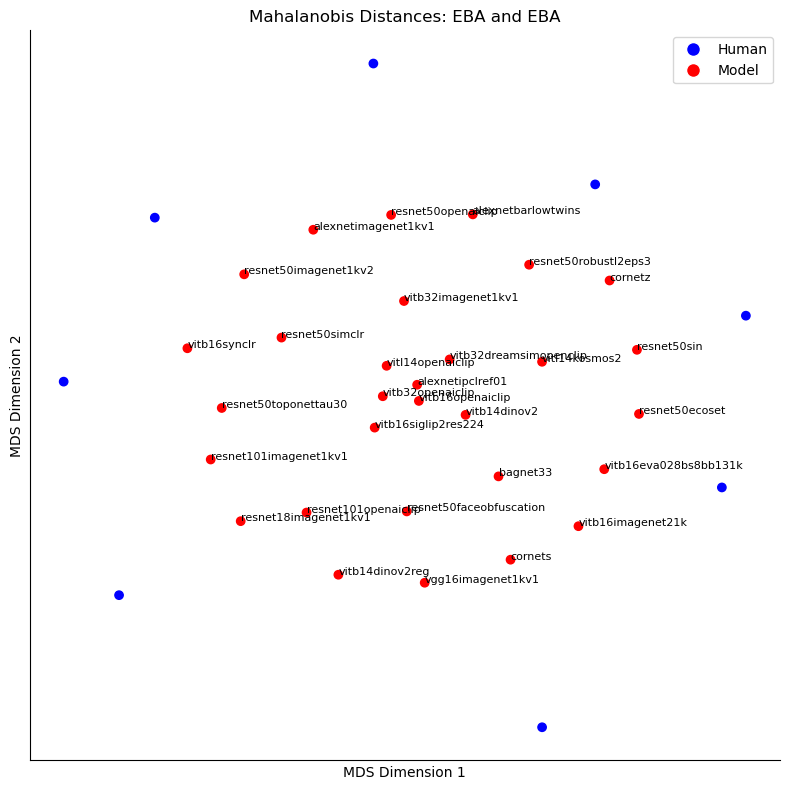

In [55]:
annotate_models = True

for (model_froi, fmri_froi) in model_fmri_frois:
    print(f'Computing MDS for {model_froi} and {fmri_froi}')
    froi_subjects_data = subjects_data[fmri_froi]
    froi_models_data = models_data[(model_froi, fmri_froi)]
    # Ignore resnet50imagenet21k model
    if 'resnet50imagenet21k' in froi_models_data:
        print(f"Ignoring resnet50imagenet21k model for {model_froi} and {fmri_froi}")
        del froi_models_data['resnet50imagenet21k']
    froi_subjects_splithalf_pearsonrs = subjects_splithalf_pearsonrs[fmri_froi]

    keys = list(froi_subjects_data.keys()) + list(froi_models_data.keys())
    froi_splithalf_pearsonr_vector = []
    for key in keys:
        if key in froi_subjects_splithalf_pearsonrs:
            froi_splithalf_pearsonr_vector.append(froi_subjects_splithalf_pearsonrs[key])
        elif key in froi_models_data:
            froi_splithalf_pearsonr_vector.append(1)

    # Compute reliability matrix
    reliability_vector = torch.tensor(froi_splithalf_pearsonr_vector)
    reliability_matrix = torch.sqrt(reliability_vector[:, None] * reliability_vector[None, :])
    # Ensure diagonal elements are 1
    diag_indices = torch.arange(reliability_matrix.shape[0])
    reliability_matrix[diag_indices, diag_indices] = 1.0

    responses = []
    for key in keys:
        if key in froi_subjects_data:
            responses.append(froi_subjects_data[key])
        elif key in froi_models_data:
            responses.append(froi_models_data[key])

    responses = torch.stack(responses, dim=0)
    responses = responses.cuda()

    # Calculate covariance matrix with regularization
    X = responses
    X_mean = torch.mean(X, dim=0, keepdim=True)
    X_centered = X - X_mean
    
    # Calculate covariance matrix
    cov_matrix = (X_centered.T @ X_centered) / (X.shape[0] - 1)
    
    # Add regularization (shrinkage)
    reg_param = 0.01  # Regularization parameter
    identity = torch.eye(cov_matrix.shape[0], device=cov_matrix.device)
    cov_matrix_reg = cov_matrix + reg_param * torch.diag(torch.diag(cov_matrix)) + 1e-6 * identity
    
    # Compute inverse of regularized covariance matrix
    try:
        inv_cov_matrix = torch.linalg.inv(cov_matrix_reg)
    except:
        print("Warning: Matrix inversion failed, using pseudo-inverse")
        inv_cov_matrix = torch.linalg.pinv(cov_matrix_reg)

    # Compute pairwise Mahalanobis distances
    n_systems = responses.shape[0]
    distances = torch.zeros((n_systems, n_systems), device=responses.device)

    for i in range(n_systems):
        for j in range(i + 1, n_systems):
            diff = X[i] - X[j]
            dist = torch.sqrt(torch.abs(diff @ inv_cov_matrix @ diff.T))
            distances[i, j] = dist
            distances[j, i] = dist  # Symmetric matrix

    # Normalize distances
    normed_distances = distances / reliability_matrix.to(distances.device)

    # Ensure no negative values
    epsilon = 1e-5
    print(f'{normed_distances[normed_distances<=0].numel()} out of {normed_distances.numel()} values are negative, clamping to {epsilon}')
    normed_distances = torch.clamp(normed_distances, min=epsilon)

    mds = MDS(n_components=2, dissimilarity='precomputed')
    mds_coords = mds.fit_transform(normed_distances.cpu().numpy())

    # Test if MDS distances are correct
    mds_coords_tensor = torch.tensor(mds_coords)
    n_systems = len(keys)
    lowdim_distances = torch.zeros((n_systems, n_systems))
    for i in range(n_systems):
        for j in range(i + 1, n_systems):
            dist = torch.norm(mds_coords_tensor[i] - mds_coords_tensor[j])
            lowdim_distances[i, j] = dist
            lowdim_distances[j, i] = dist
    print('Stress:', calculate_stress(normed_distances.cpu(), lowdim_distances))

    # Find which indices correspond to subjects and which to models
    subject_indices = [i for i, key in enumerate(keys) if key in froi_subjects_data]
    model_indices = [i for i, key in enumerate(keys) if key in froi_models_data]

    # Calculate mean distances from each model to all subjects
    model_to_subjects_orig = torch.zeros(len(model_indices))
    model_to_subjects_mds = torch.zeros(len(model_indices))

    for i, model_idx in enumerate(model_indices):
        model_to_subjects_orig[i] = normed_distances[model_idx, subject_indices].cpu().mean()
        model_to_subjects_mds[i] = lowdim_distances[model_idx, subject_indices].mean()

    # Calculate Spearman rank correlation
    sp_corr, p_value = spearmanr(model_to_subjects_orig.numpy(), model_to_subjects_mds.numpy())
    print(f"Spearman rank correlation between original and MDS distances: {sp_corr:.3f} (p={p_value:.3e})")

    human_color = 'blue'
    model_color = 'red'
    colors = [human_color if key in froi_subjects_data else model_color for key in keys]
    plt.figure(figsize=(8, 8))
    plt.scatter(mds_coords[:, 0], mds_coords[:, 1], c=colors)

    if annotate_models:
        for i, key in enumerate(keys):
            if key in froi_models_data:
                plt.annotate(key, (mds_coords[i, 0], mds_coords[i, 1]), fontsize=8)

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.xticks([])
    plt.yticks([])
    plt.xlabel('MDS Dimension 1')
    plt.ylabel('MDS Dimension 2')
    plt.legend(handles=[plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=human_color, markersize=10, label='Human'),
                        plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=model_color, markersize=10, label='Model')],
               loc='best')
    plt.title(f'Mahalanobis Distances: {model_froi} and {fmri_froi}')
    plt.tight_layout()
    plt.show()

## Normalized mahlanobis distances

Computing MDS for FFA and FFA
38 out of 1444 values are negative, clamping to 1e-05
Stress: 0.32344070076942444
Spearman rank correlation between original and MDS distances: 0.894 (p=2.828e-11)


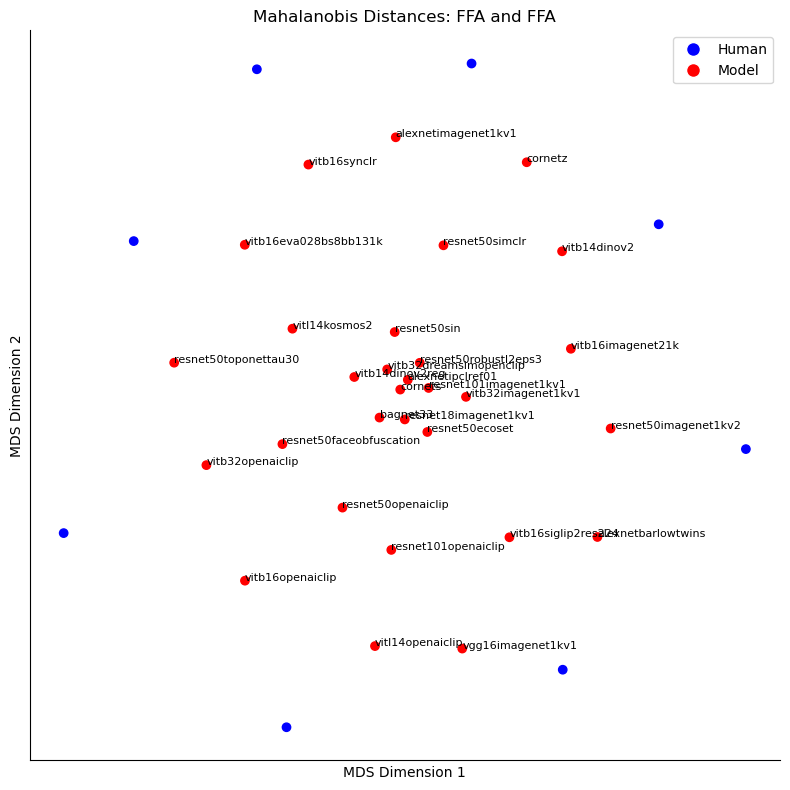

Computing MDS for PPA and PPA
38 out of 1444 values are negative, clamping to 1e-05
Stress: 0.3310500383377075
Spearman rank correlation between original and MDS distances: 0.828 (p=1.610e-08)


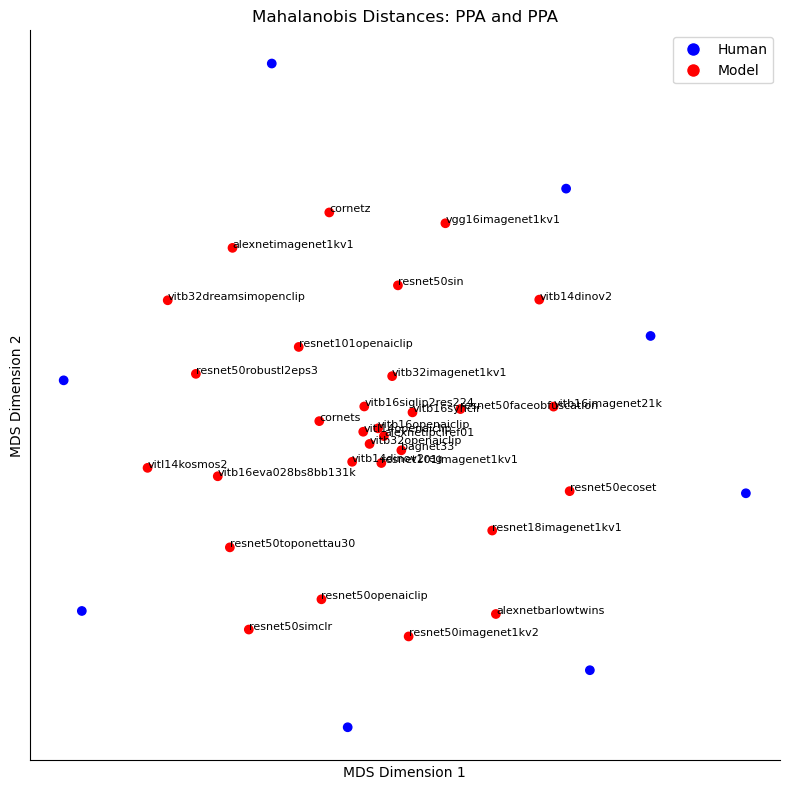

Computing MDS for EBA and EBA
38 out of 1444 values are negative, clamping to 1e-05
Stress: 0.35510432720184326
Spearman rank correlation between original and MDS distances: 0.850 (p=2.775e-09)


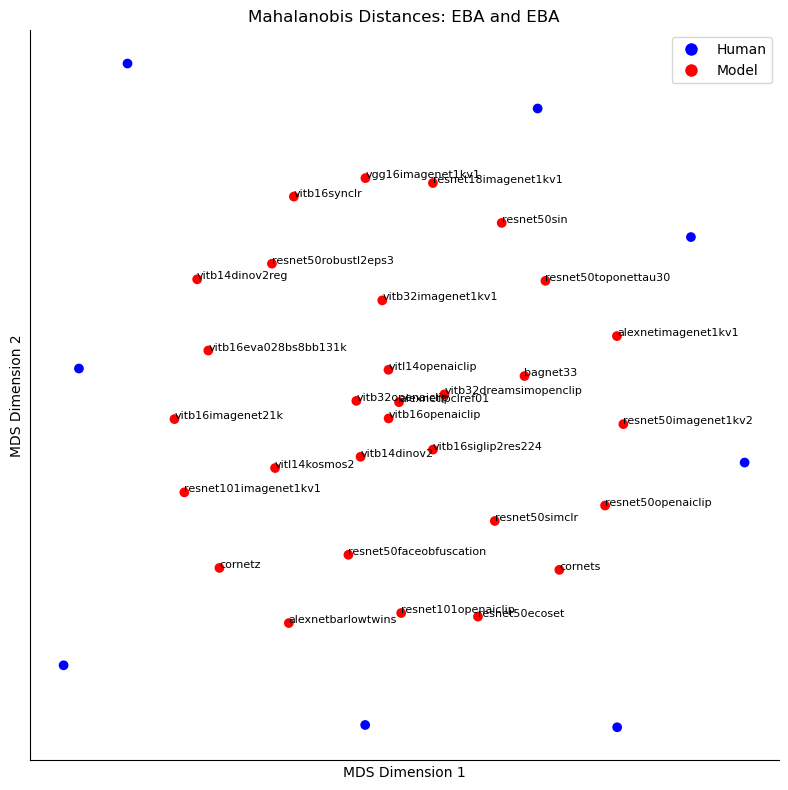

In [56]:
annotate_models = True

for (model_froi, fmri_froi) in model_fmri_frois:
    print(f'Computing MDS for {model_froi} and {fmri_froi}')
    froi_subjects_data = subjects_data[fmri_froi]
    froi_models_data = models_data[(model_froi, fmri_froi)]
    # Ignore resnet50imagenet21k model
    if 'resnet50imagenet21k' in froi_models_data:
        print(f"Ignoring resnet50imagenet21k model for {model_froi} and {fmri_froi}")
        del froi_models_data['resnet50imagenet21k']
    froi_subjects_splithalf_pearsonrs = subjects_splithalf_pearsonrs[fmri_froi]

    keys = list(froi_subjects_data.keys()) + list(froi_models_data.keys())
    froi_splithalf_pearsonr_vector = []
    for key in keys:
        if key in froi_subjects_splithalf_pearsonrs:
            froi_splithalf_pearsonr_vector.append(froi_subjects_splithalf_pearsonrs[key])
        elif key in froi_models_data:
            froi_splithalf_pearsonr_vector.append(1)

    # Compute reliability matrix
    reliability_vector = torch.tensor(froi_splithalf_pearsonr_vector)
    reliability_matrix = torch.sqrt(reliability_vector[:, None] * reliability_vector[None, :])
    # Ensure diagonal elements are 1
    diag_indices = torch.arange(reliability_matrix.shape[0])
    reliability_matrix[diag_indices, diag_indices] = 1.0

    responses = []
    for key in keys:
        if key in froi_subjects_data:
            responses.append(froi_subjects_data[key])
        elif key in froi_models_data:
            responses.append(froi_models_data[key])

    responses = torch.stack(responses, dim=0)
    responses = responses.cuda()

    # Calculate covariance matrix with regularization
    X = responses
    X_mean = torch.mean(X, dim=0, keepdim=True)
    X_centered = X - X_mean
    
    # Calculate covariance matrix
    cov_matrix = (X_centered.T @ X_centered) / (X.shape[0] - 1)
    
    # Add regularization (shrinkage)
    reg_param = 0.01  # Regularization parameter
    identity = torch.eye(cov_matrix.shape[0], device=cov_matrix.device)
    cov_matrix_reg = cov_matrix + reg_param * torch.diag(torch.diag(cov_matrix)) + 1e-6 * identity
    
    # Compute inverse of regularized covariance matrix
    try:
        inv_cov_matrix = torch.linalg.inv(cov_matrix_reg)
    except:
        print("Warning: Matrix inversion failed, using pseudo-inverse")
        inv_cov_matrix = torch.linalg.pinv(cov_matrix_reg)

    # Compute pairwise Mahalanobis distances
    n_systems = responses.shape[0]
    distances = torch.zeros((n_systems, n_systems), device=responses.device)

    for i in range(n_systems):
        for j in range(i + 1, n_systems):
            diff = X[i] - X[j]
            dist = torch.sqrt(torch.abs(diff @ inv_cov_matrix @ diff.T))
            distances[i, j] = dist
            distances[j, i] = dist  # Symmetric matrix

    # Normalize distances
    normed_distances = distances / reliability_matrix.to(distances.device)

    # Ensure no negative values
    epsilon = 1e-5
    print(f'{normed_distances[normed_distances<=0].numel()} out of {normed_distances.numel()} values are negative, clamping to {epsilon}')
    normed_distances = torch.clamp(normed_distances, min=epsilon)

    mds = MDS(n_components=2, dissimilarity='precomputed')
    mds_coords = mds.fit_transform(normed_distances.cpu().numpy())

    # Test if MDS distances are correct
    mds_coords_tensor = torch.tensor(mds_coords)
    n_systems = len(keys)
    lowdim_distances = torch.zeros((n_systems, n_systems))
    for i in range(n_systems):
        for j in range(i + 1, n_systems):
            dist = torch.norm(mds_coords_tensor[i] - mds_coords_tensor[j]) * reliability_matrix[i, j]
            lowdim_distances[i, j] = dist
            lowdim_distances[j, i] = dist
    print('Stress:', calculate_stress(normed_distances.cpu(), lowdim_distances))

    # Find which indices correspond to subjects and which to models
    subject_indices = [i for i, key in enumerate(keys) if key in froi_subjects_data]
    model_indices = [i for i, key in enumerate(keys) if key in froi_models_data]

    # Calculate mean distances from each model to all subjects
    model_to_subjects_orig = torch.zeros(len(model_indices))
    model_to_subjects_mds = torch.zeros(len(model_indices))

    for i, model_idx in enumerate(model_indices):
        model_to_subjects_orig[i] = normed_distances[model_idx, subject_indices].cpu().mean()
        model_to_subjects_mds[i] = lowdim_distances[model_idx, subject_indices].mean()

    # Calculate Spearman rank correlation
    sp_corr, p_value = spearmanr(model_to_subjects_orig.numpy(), model_to_subjects_mds.numpy())
    print(f"Spearman rank correlation between original and MDS distances: {sp_corr:.3f} (p={p_value:.3e})")

    human_color = 'blue'
    model_color = 'red'
    colors = [human_color if key in froi_subjects_data else model_color for key in keys]
    plt.figure(figsize=(8, 8))
    plt.scatter(mds_coords[:, 0], mds_coords[:, 1], c=colors)

    if annotate_models:
        for i, key in enumerate(keys):
            if key in froi_models_data:
                plt.annotate(key, (mds_coords[i, 0], mds_coords[i, 1]), fontsize=8)

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.xticks([])
    plt.yticks([])
    plt.xlabel('MDS Dimension 1')
    plt.ylabel('MDS Dimension 2')
    plt.legend(handles=[plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=human_color, markersize=10, label='Human'),
                        plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=model_color, markersize=10, label='Model')],
               loc='best')
    plt.title(f'Mahalanobis Distances: {model_froi} and {fmri_froi}')
    plt.tight_layout()
    plt.show()